# HPC Anomaly Detection — V7: One Global Isolation Forest, Per-Node Thresholds

**Purpose:** Keep one shared Isolation Forest trained across the cluster, but calibrate a separate alert threshold for each node.

V7 tests whether node-specific score distributions—especially the headnode versus compute nodes—are causing the uneven alert rates seen with V6.

## What this notebook will do
1. Load the V6 engineered telemetry and labels.
2. Create chronological train / validation / test partitions by timestamp.
3. Fit **one global Isolation Forest** on clean normal training rows from all nodes.
4. Calculate anomaly scores for every partition.
5. Select one threshold per node using validation F1 when validation has both classes; otherwise use that node's clean-training score quantile.
6. Evaluate operational events, the broad anomaly label, and benchmark-active workload periods with the frozen node thresholds.
7. Compare against a single global threshold and export a V7 model bundle and report.

**Important:** Thresholds change which observations are alerted. They do not improve the physical cluster, fix hardware, or increase compute performance. V7 can improve alert calibration, not cluster performance itself.

**Evaluation caution:** The previous V6 validation interval contained zero operational-event positives. If that is still true, this notebook will use the per-node clean-training 99th percentile fallback. It will not tune thresholds using test labels. The test interval has already been inspected in earlier V6 diagnostics, so treat V7 test results as development diagnostics rather than a pristine final holdout. A future untouched period is needed for a final unbiased comparison.

**Review improvements:** Exact telemetry/label key alignment is checked; features are selected from the telemetry Parquet only; validation-F1 calibration requires multiple labelled rows and distinct events; alert episode burden is exported.

The `is_benchmark_active` metric is a labelled workload/benchmark proxy. It is not a claim that every high-utilisation period in the cluster is represented by that label.

## 1. Environment and paths

Run the V6 feature-engineering notebook first. Confirm that the two Parquet files below exist. If your files are in a different folder, edit `DATA_DIR`.

Required packages: `pandas`, `numpy`, `pyarrow`, `scikit-learn`, `matplotlib`, and `joblib`.

In [1]:
%pip install -q pandas numpy pyarrow scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score, precision_score, recall_score, f1_score,
    confusion_matrix, precision_recall_curve
)

warnings.filterwarnings("ignore", category=UserWarning)

# Update these paths if your folders are different.
DATA_DIR = Path(
    r"C:/Users/Admin/Documents/chpc/capstone project/data/feature_engineering_duckdb_v6"
)
MODEL_DIR = Path(
    r"C:/Users/Admin/Documents/chpc/capstone project/models"
)
REPORT_DIR = DATA_DIR / "v7_per_node_threshold_report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TELEMETRY_FILE = DATA_DIR / "model_input_1min_v6.parquet"
LABEL_FILE = DATA_DIR / "labels_1min_v6.parquet"

NODE_COLUMN = "node_id"
TIME_COLUMN = "minute_utc"
TARGETS = ["operational_event_window", "is_any_anomaly", "is_benchmark_active"]

TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
RANDOM_STATE = 42
N_ESTIMATORS = 300

# Threshold calibration fallback. Quantile is calculated from CLEAN TRAIN scores
# for each node, never from test labels or test scores.
FALLBACK_QUANTILE = 0.99

print("Data directory:", DATA_DIR)
print("Telemetry exists:", TELEMETRY_FILE.exists())
print("Labels exist:", LABEL_FILE.exists())
print("Report directory:", REPORT_DIR)
# Candidate model features will be taken from the telemetry Parquet only, never
# from label-only columns introduced by the merge.
TELEMETRY_COLUMNS = []

# Validation F1 is too unstable when based on only a handful of labelled rows
# or a single event. In that case, use the clean-training score quantile.
MIN_VALIDATION_POSITIVE_ROWS = 10
MIN_VALIDATION_EVENT_IDS = 2


Data directory: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6
Telemetry exists: True
Labels exist: True
Report directory: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\v7_per_node_threshold_report


## 2. Load and align telemetry with labels

The join must be one-to-one on `node_id` and `minute_utc`. If this fails, investigate duplicate keys rather than silently dropping rows.

In [3]:
def load_data():
    global TELEMETRY_COLUMNS

    if not TELEMETRY_FILE.exists():
        raise FileNotFoundError(f"Missing telemetry file: {TELEMETRY_FILE}")
    if not LABEL_FILE.exists():
        raise FileNotFoundError(f"Missing labels file: {LABEL_FILE}")

    telemetry = pd.read_parquet(TELEMETRY_FILE)
    labels = pd.read_parquet(LABEL_FILE)

    required_keys = [NODE_COLUMN, TIME_COLUMN]
    for key in required_keys:
        if key not in telemetry.columns or key not in labels.columns:
            raise KeyError(f"Join key {key!r} must exist in both Parquet files.")

    telemetry[TIME_COLUMN] = pd.to_datetime(telemetry[TIME_COLUMN], utc=True)
    labels[TIME_COLUMN] = pd.to_datetime(labels[TIME_COLUMN], utc=True)

    # Reject duplicate keys before joining. An inner join alone could silently
    # discard unmatched rows and make the training/evaluation population unclear.
    for name, frame in [("telemetry", telemetry), ("labels", labels)]:
        duplicate_count = int(frame.duplicated(required_keys).sum())
        if duplicate_count:
            raise ValueError(f"{name} has {duplicate_count:,} duplicate node/minute keys.")

    key_audit = telemetry[required_keys].merge(
        labels[required_keys], on=required_keys, how="outer",
        indicator=True, validate="one_to_one"
    )
    unmatched = key_audit["_merge"].value_counts().to_dict()
    if (key_audit["_merge"] != "both").any():
        raise ValueError(
            "Telemetry and label keys do not align exactly. "
            f"Key audit: {unmatched}. Resolve this before model training."
        )

    TELEMETRY_COLUMNS = telemetry.columns.tolist()
    df = telemetry.merge(
        labels,
        on=required_keys,
        how="inner",
        validate="one_to_one",
        suffixes=("", "_label")
    )

    if df.empty:
        raise ValueError("The telemetry/label join returned zero rows.")

    df = df.sort_values([TIME_COLUMN, NODE_COLUMN]).reset_index(drop=True)
    print(f"Rows: {len(df):,}")
    print(f"Nodes: {sorted(df[NODE_COLUMN].dropna().unique().tolist())}")
    print(f"Time range: {df[TIME_COLUMN].min()} to {df[TIME_COLUMN].max()}")
    print("Telemetry/label key audit:", unmatched)

    for target in TARGETS:
        if target in df.columns:
            print(f"{target}: {int(df[target].fillna(0).sum()):,} positive rows")
        else:
            print(f"WARNING: target not present: {target}")

    return df

df = load_data()


Rows: 80,640
Nodes: ['compute001', 'compute002', 'compute003', 'headnode']
Time range: 2026-10-18 00:00:00+00:00 to 2026-10-31 23:59:00+00:00
Telemetry/label key audit: {'both': 80640, 'left_only': 0, 'right_only': 0}
operational_event_window: 183 positive rows
is_any_anomaly: 1,444 positive rows
is_benchmark_active: 205 positive rows


## 3. Chronological data split

All nodes at the same timestamp are assigned to the same partition. This avoids training on one node's observation at a time that appears in the test set for another node.

In [4]:
# Split by unique timestamps, not rows, so all nodes at a minute remain
# in the same chronological partition.
unique_times = np.array(sorted(df[TIME_COLUMN].dropna().unique()))
n_times = len(unique_times)
train_end = int(n_times * TRAIN_FRACTION)
val_end = int(n_times * (TRAIN_FRACTION + VALIDATION_FRACTION))

train_end_time = unique_times[train_end - 1]
val_end_time = unique_times[val_end - 1]

train_df = df[df[TIME_COLUMN] <= train_end_time].copy()
val_df = df[(df[TIME_COLUMN] > train_end_time) & (df[TIME_COLUMN] <= val_end_time)].copy()
test_df = df[df[TIME_COLUMN] > val_end_time].copy()

print("Train:", len(train_df), train_df[TIME_COLUMN].min(), "to", train_df[TIME_COLUMN].max())
print("Validation:", len(val_df), val_df[TIME_COLUMN].min(), "to", val_df[TIME_COLUMN].max())
print("Test:", len(test_df), test_df[TIME_COLUMN].min(), "to", test_df[TIME_COLUMN].max())

for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"\\n{name.upper()}")
    for target in TARGETS:
        if target in part:
            print(target, "positives =", int(part[target].fillna(0).sum()))

Train: 56448 2026-10-18 00:00:00+00:00 to 2026-10-27 19:11:00+00:00
Validation: 12096 2026-10-27 19:12:00+00:00 to 2026-10-29 21:35:00+00:00
Test: 12096 2026-10-29 21:36:00+00:00 to 2026-10-31 23:59:00+00:00
\nTRAIN
operational_event_window positives = 130
is_any_anomaly positives = 1186
is_benchmark_active positives = 0
\nVALIDATION
operational_event_window positives = 0
is_any_anomaly positives = 7
is_benchmark_active positives = 7
\nTEST
operational_event_window positives = 53
is_any_anomaly positives = 251
is_benchmark_active positives = 198


## 4. Feature selection and imputation

Only numeric telemetry features are used. Identifiers, timestamps, labels, event metadata, and training masks are excluded. Imputation medians are learned from training data only.

In [5]:
# Build the feature list from the telemetry input file only. This prevents
# label-only columns from leaking into the model after the labels merge.
NON_FEATURE_COLUMNS = {
    NODE_COLUMN, TIME_COLUMN,
    "event_id", "event_class", "event_phase",
    "operational_event_observed", "operational_event_window",
    "is_any_anomaly", "is_anomaly", "is_failure",
    "is_benchmark_active", "is_unlabelled_stress_burst",
    "planned_maintenance", "node_available",
    "temperature_sensor_missing", "failure_within_1h", "failure_within_6h",
    "minute_overlap_fraction", "exclude_from_normal_train",
    "split"
}

feature_columns = [
    c for c in TELEMETRY_COLUMNS
    if c in df.columns
    and c not in NON_FEATURE_COLUMNS
    and not c.endswith("_label")
    and pd.api.types.is_numeric_dtype(df[c])
]
if not feature_columns:
    raise ValueError("No numeric telemetry features found. Review the model-input Parquet.")

# Guard against accidental target/label leakage.
forbidden_feature_names = set(TARGETS) | {
    "operational_event_observed", "is_failure", "is_anomaly", "event_id"
}
leaked = sorted(set(feature_columns) & forbidden_feature_names)
if leaked:
    raise ValueError(f"Label leakage detected in feature list: {leaked}")

# Fit imputation values on training data only.
imputation_medians = train_df[feature_columns].median()
imputation_medians = imputation_medians.fillna(0.0)

def make_matrix(part):
    return (
        part[feature_columns]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(imputation_medians)
        .astype(float)
    )

X_train = make_matrix(train_df)
X_val = make_matrix(val_df)
X_test = make_matrix(test_df)

print("Number of telemetry features:", len(feature_columns))
print(feature_columns)


Number of telemetry features: 28
['cpu_utilisation_pct_mean', 'iowait_pct_mean', 'memory_used_pct_mean', 'network_rx_mib_s_mean', 'network_tx_mib_s_mean', 'tcp_retrans_per_s_mean', 'disk_read_mib_s_mean', 'disk_write_mib_s_mean', 'disk_io_time_pct_sum_mean', 'disk_io_now_mean', 'node_procs_running_mean', 'is_nonzero_disk_write_mib_s_mean', 'is_nonzero_disk_io_now_mean', 'is_nonzero_iowait_pct_mean', 'is_nonzero_tcp_retrans_per_s_mean', 'memory_used_delta_1h', 'root_fs_used_delta_1h', 'node_down_in_minute', 'scrape_shortfall_in_minute', 'collector_shortfall_pct_mean', 'failed_active_collectors_max', 'scrape_duration_seconds_max', 'cpu_utilisation_pct_mean_peer_diff', 'node_load1_per_core_mean_peer_diff', 'disk_write_mib_s_mean_peer_diff', 'scrape_duration_seconds_max_peer_diff', 'node_load1_per_core_mean_zscore_15m', 'scrape_duration_seconds_max_zscore_15m']


## 5. Select clean normal training rows

The model should learn normal telemetry patterns. Inspect the clean-row count and the mask semantics in your feature-engineering notebook before trusting the result.

In [6]:
# Start with the feature-engineering exclusion mask if available.
if "exclude_from_normal_train" in train_df.columns:
    clean_train_mask = ~train_df["exclude_from_normal_train"].fillna(True).astype(bool)
else:
    clean_train_mask = pd.Series(True, index=train_df.index)

# Independently remove any rows already labelled as operational or broad
# anomalies. This protects against a stale/incomplete exclusion mask.
known_anomaly_columns = [
    "operational_event_window",
    "is_any_anomaly",
    "is_benchmark_active",
    "is_unlabelled_stress_burst"
]
for col in known_anomaly_columns:
    if col in train_df.columns:
        clean_train_mask &= train_df[col].fillna(0).astype(int).eq(0)

if "planned_maintenance" in train_df.columns:
    clean_train_mask &= ~train_df["planned_maintenance"].fillna(0).astype(bool)
if "node_available" in train_df.columns:
    # Unknown availability is not assumed to be healthy for normal-model fitting.
    clean_train_mask &= train_df["node_available"].fillna(0).astype(bool)

print("Training rows:", len(train_df))
print("Clean rows selected for model fitting:", int(clean_train_mask.sum()))
print("Rows excluded from normal fitting:", int((~clean_train_mask).sum()))
if clean_train_mask.sum() < 100:
    raise ValueError("Too few clean training rows. Inspect the training mask and label semantics.")


Training rows: 56448
Clean rows selected for model fitting: 55262
Rows excluded from normal fitting: 1186


## 6. Fit one global Isolation Forest

This is one model for all nodes. Node identity is not passed as a numeric feature; node-specific calibration happens after scoring.

In [7]:
global_model = IsolationForest(
    n_estimators=N_ESTIMATORS,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    bootstrap=False,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

fit_rows = X_train.loc[clean_train_mask]
start = time.time()
global_model.fit(fit_rows)
fit_seconds = time.time() - start

def anomaly_score(model, X):
    # Higher values mean more anomalous.
    return -model.score_samples(X)

train_scores = pd.Series(
    anomaly_score(global_model, X_train), index=train_df.index, name="anomaly_score"
)
val_scores = pd.Series(
    anomaly_score(global_model, X_val), index=val_df.index, name="anomaly_score"
)
test_scores = pd.Series(
    anomaly_score(global_model, X_test), index=test_df.index, name="anomaly_score"
)

print(f"Global model fit rows: {len(fit_rows):,}")
print(f"Fit time: {fit_seconds:.2f} seconds")
print("Score ranges:")
print("train", train_scores.min(), train_scores.max())
print("validation", val_scores.min(), val_scores.max())
print("test", test_scores.min(), test_scores.max())

Global model fit rows: 55,262
Fit time: 1.51 seconds
Score ranges:
train 0.33712206620745044 0.816666198825656
validation 0.35543487409085406 0.7904932843936666
test 0.3577501316671999 0.7982571385598604


## 7. Calibrate one threshold per node

For each node:
- If its validation rows contain both positive and negative examples for the **calibration target** (`operational_event_window` by default), choose the threshold that maximises validation F1.
- Otherwise, use the 99th percentile of that node's **clean training scores**.

Do not change the calibration target after looking at test results. If validation has no operational positives, the fallback is expected and should be reported transparently.

In [8]:
def binary_metrics(y_true, y_pred, scores, calculate_ap=True):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    scores = np.asarray(scores, dtype=float)

    # sklearn's average_precision_score is Average Precision (AP), a standard
    # summary of the precision-recall curve; it is not trapezoidal PR-AUC.
    ap = (
        average_precision_score(y_true, scores)
        if calculate_ap and np.unique(y_true).size == 2
        else np.nan
    )
    return {
        "rows": int(len(y_true)),
        "positives": int(y_true.sum()),
        "predicted_anomalies": int(y_pred.sum()),
        "average_precision_ap": float(ap) if np.isfinite(ap) else np.nan,
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist()
    }


def choose_threshold(validation_scores, validation_labels, clean_training_scores,
                     validation_event_ids=None,
                     fallback_quantile=FALLBACK_QUANTILE):
    """Calibrate using validation F1 only with enough independent label support.

    If validation has too few positive rows, too few distinct positive events,
    or only one class, use the clean-training score quantile. Test data is never
    passed into this function.
    """
    scores = np.asarray(validation_scores, dtype=float)
    labels = np.asarray(validation_labels).astype(int)
    positive_rows = int(labels.sum())

    if validation_event_ids is None:
        positive_event_count = 0
    else:
        event_ids = pd.Series(validation_event_ids).reset_index(drop=True)
        positive_mask = pd.Series(labels).eq(1)
        positive_event_count = int(event_ids[positive_mask].dropna().nunique())

    enough_support = (
        positive_rows >= MIN_VALIDATION_POSITIVE_ROWS
        and positive_event_count >= MIN_VALIDATION_EVENT_IDS
    )

    if len(np.unique(labels)) == 2 and enough_support:
        precision, recall, thresholds = precision_recall_curve(labels, scores)
        if len(thresholds):
            f1_values = (
                2 * precision[:-1] * recall[:-1] /
                np.maximum(precision[:-1] + recall[:-1], 1e-12)
            )
            best_idx = int(np.nanargmax(f1_values))
            return float(thresholds[best_idx]), "validation_max_f1"

    fallback = np.asarray(clean_training_scores, dtype=float)
    if len(fallback) == 0:
        raise ValueError("Cannot calibrate threshold: no clean-training scores.")
    return float(np.quantile(fallback, fallback_quantile)), f"clean_train_q{fallback_quantile}"


def macro_node_average_precision(y, scores, nodes):
    """Mean AP over nodes with both positive and negative examples.

    Appropriate when node models have different score scales. Nodes without
    both classes are excluded and the count of included nodes is returned.
    """
    frame = pd.DataFrame({
        "y": np.asarray(y).astype(int),
        "score": np.asarray(scores, dtype=float),
        "node": np.asarray(nodes).astype(str)
    })
    aps = []
    for node, group in frame.groupby("node"):
        if group["y"].nunique() == 2:
            aps.append(average_precision_score(group["y"], group["score"]))
    return (float(np.mean(aps)) if aps else np.nan, len(aps))


def alert_burden(scored):
    """Count flagged minutes and consecutive-minute alert episodes per node."""
    work = scored[[NODE_COLUMN, TIME_COLUMN, "predicted_anomaly"]].copy()
    work = work.sort_values([NODE_COLUMN, TIME_COLUMN])
    grouped = work.groupby(NODE_COLUMN, sort=False)
    previous_time = grouped[TIME_COLUMN].shift(1)
    previous_flag = grouped["predicted_anomaly"].shift(1).fillna(0).astype(int)
    continuous = (work[TIME_COLUMN] - previous_time) == pd.Timedelta(minutes=1)
    starts_episode = (
        work["predicted_anomaly"].eq(1)
        & ~((previous_flag == 1) & continuous)
    )
    work["episode_start"] = starts_episode.astype(int)

    rows = []
    for node, group in work.groupby(NODE_COLUMN):
        elapsed_hours = (
            (group[TIME_COLUMN].max() - group[TIME_COLUMN].min()).total_seconds() / 3600
            + (1 / 60)
        )
        elapsed_hours = max(elapsed_hours, 1 / 60)
        flagged = int(group["predicted_anomaly"].sum())
        episodes = int(group["episode_start"].sum())
        rows.append({
            "node_id": node,
            "observed_hours": elapsed_hours,
            "flagged_minutes": flagged,
            "alert_episodes": episodes,
            "flagged_minutes_per_hour": flagged / elapsed_hours,
            "alert_episodes_per_hour": episodes / elapsed_hours
        })
    return pd.DataFrame(rows)


In [9]:
CALIBRATION_TARGET = "operational_event_window"
if CALIBRATION_TARGET not in df.columns:
    raise KeyError(f"Missing calibration target: {CALIBRATION_TARGET}")

node_thresholds = {}
threshold_rows = []

for node in sorted(df[NODE_COLUMN].dropna().unique()):
    train_node = train_df[NODE_COLUMN].eq(node)
    val_node = val_df[NODE_COLUMN].eq(node)
    clean_node = train_node & clean_train_mask

    clean_scores = train_scores.loc[clean_node]
    val_node_scores = val_scores.loc[val_node]
    val_node_labels = val_df.loc[val_node, CALIBRATION_TARGET].fillna(0).astype(int)
    val_event_ids = (
        val_df.loc[val_node, "event_id"]
        if "event_id" in val_df.columns else None
    )

    if len(clean_scores) == 0:
        raise ValueError(f"No clean training scores for node {node}")

    threshold, source = choose_threshold(
        val_node_scores,
        val_node_labels,
        clean_scores,
        validation_event_ids=val_event_ids,
        fallback_quantile=FALLBACK_QUANTILE
    )
    node_thresholds[node] = threshold

    positive_event_count = (
        int(val_event_ids[val_node_labels.to_numpy() == 1].dropna().nunique())
        if val_event_ids is not None else 0
    )
    threshold_rows.append({
        "node_id": node,
        "threshold": threshold,
        "threshold_source": source,
        "clean_train_rows": int(len(clean_scores)),
        "validation_rows": int(val_node.sum()),
        "validation_operational_positives": int(val_node_labels.sum()),
        "validation_positive_event_ids": positive_event_count,
        "clean_train_score_p50": float(clean_scores.quantile(0.50)),
        "clean_train_score_p95": float(clean_scores.quantile(0.95)),
        "clean_train_score_p99": float(clean_scores.quantile(0.99)),
        "clean_train_score_max": float(clean_scores.max())
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)
threshold_table.to_csv(REPORT_DIR / "v7_node_thresholds.csv", index=False)


,node_id,threshold,threshold_source,clean_train_rows,validation_rows,validation_operational_positives,validation_positive_event_ids,clean_train_score_p50,clean_train_score_p95,clean_train_score_p99,clean_train_score_max
0,compute001,0.541812,clean_train_q0.99,13264,3024,0,0,0.382814,0.486687,0.541812,0.761243
1,compute002,0.534974,clean_train_q0.99,13999,3024,0,0,0.357393,0.450979,0.534974,0.770526
2,compute003,0.522034,clean_train_q0.99,14029,3024,0,0,0.358655,0.451466,0.522034,0.751074
3,headnode,0.661564,clean_train_q0.99,13970,3024,0,0,0.460427,0.579056,0.661564,0.771987


## 8. Apply frozen thresholds to each partition

The same node threshold is used for that node in train, validation, and test. No threshold is recalculated from test scores or labels.

In [10]:
def apply_node_thresholds(part, scores, thresholds):
    out = part[[NODE_COLUMN, TIME_COLUMN]].copy()
    out["anomaly_score"] = scores.reindex(part.index).to_numpy()
    out["threshold"] = out[NODE_COLUMN].map(thresholds)
    out["predicted_anomaly"] = (out["anomaly_score"] >= out["threshold"]).astype(int)
    return out

train_scored = apply_node_thresholds(train_df, train_scores, node_thresholds)
val_scored = apply_node_thresholds(val_df, val_scores, node_thresholds)
test_scored = apply_node_thresholds(test_df, test_scores, node_thresholds)

for target in TARGETS:
    if target in test_df.columns:
        test_scored[target] = test_df[target].fillna(0).astype(int).to_numpy()

print("Test rows:", len(test_scored))
print("Test flags:", int(test_scored["predicted_anomaly"].sum()))
display(test_scored.groupby(NODE_COLUMN)["predicted_anomaly"].agg(["sum", "mean"]))

Test rows: 12096
Test flags: 1902


,sum,mean
node_id,,
compute001,281,0.092923
compute002,593,0.196098
compute003,779,0.257606
headnode,249,0.082341


## 9. Evaluate both label definitions

- `operational_event_window`: matches the event-window definition in the labels file. Check whether it includes planned stress tests or other non-failure events before calling this a failure metric.
- `is_any_anomaly`: a broader target. Verify its exact construction; do not automatically describe it as pure high utilisation.
- `is_benchmark_active`: benchmark/workload periods are evaluated separately as a proxy for high-activity detection. This label may not cover every type of busy workload.

Average Precision (AP), calculated with scikit-learn's average_precision_score, uses continuous scores and does not depend on the threshold. It is a standard PR-curve summary, not trapezoidal PR-AUC. Precision, recall, and F1 use the frozen per-node thresholds. Precision, recall, and F1 use the frozen per-node thresholds.

In [11]:
overall_rows = []
for target in TARGETS:
    if target not in test_df.columns:
        continue
    metrics = binary_metrics(
        test_df[target].fillna(0).astype(int),
        test_scored["predicted_anomaly"],
        test_scored["anomaly_score"]
    )
    overall_rows.append({"target": target, **metrics})

overall_metrics = pd.DataFrame(overall_rows)
display(overall_metrics)
overall_metrics.to_json(REPORT_DIR / "v7_overall_test_metrics.json", orient="records", indent=2)


,target,rows,positives,predicted_anomalies,average_precision_ap,precision,recall,f1,confusion_matrix
0,operational_event_window,12096,53,1902,0.013070,0.016299,0.584906,0.031714,"[[10172, 1871], [22, 31]]"
1,is_any_anomaly,12096,251,1902,0.058602,0.085699,0.649402,0.151417,"[[10106, 1739], [88, 163]]"
2,is_benchmark_active,12096,198,1902,0.050511,0.069401,0.666667,0.125714,"[[10128, 1770], [66, 132]]"


In [13]:
# ------------------------------------------------------------------
# SECTION 9b (FIXED): Evaluate V7 against headnode event labels
# ------------------------------------------------------------------
HEADNODE_LABELS_FILE = DATA_DIR / "headnode_event_labels_v9.parquet"
if not HEADNODE_LABELS_FILE.exists():
    raise FileNotFoundError(
        f"Run the headnode label builder first: {HEADNODE_LABELS_FILE}"
    )
hn_labels = pd.read_parquet(HEADNODE_LABELS_FILE)
hn_labels["minute_utc"] = pd.to_datetime(hn_labels["minute_utc"], utc=True)

# Guard against duplicate minute_utc (which would silently expand the merge)
if hn_labels["minute_utc"].duplicated().any():
    dups = hn_labels.loc[
        hn_labels["minute_utc"].duplicated(keep=False), "minute_utc"
    ].unique()
    raise ValueError(
        f"hn_labels has {len(dups)} duplicate minute_utc values, e.g. {list(dups)[:5]}. "
        f"Rebuild the label file with .drop_duplicates(subset=['minute_utc'])."
    )

HEADNODE_TARGETS = [
    "ssh_brute_force", "admin_session_active", "apt_daily_active",
    "cron_hourly_active", "ssh_isolated_probe", "slurm_config_drift",
    "headnode_security_event", "headnode_novelty_event",
    "headnode_routine_maintenance",
]

# Merge into a copy of test_df (order is preserved for how="left")
test_df_hn = test_df.merge(hn_labels, on="minute_utc", how="left")
for t in HEADNODE_TARGETS:
    if t in test_df_hn.columns:
        test_df_hn[t] = test_df_hn[t].fillna(0).astype(int)

# ------------------------------------------------------------------
# ALIGNMENT FIX: verify row count and use positional indexing
# ------------------------------------------------------------------
if len(test_df_hn) != len(test_df):
    raise ValueError(
        f"Row count changed after merge: test_df={len(test_df)}, "
        f"test_df_hn={len(test_df_hn)}. "
        f"Check for duplicate minute_utc in hn_labels."
    )

hn_mask_arr = (test_df_hn["node_id"] == "headnode").to_numpy()
print(f"Headnode test rows: {int(hn_mask_arr.sum()):,} / {len(test_df_hn):,}")

hn_threshold = node_thresholds["headnode"]
print(f"Headnode IF threshold: {hn_threshold:.6f}")

# Positional lookup: guarantees alignment regardless of index labels
hn_scores = test_scores.to_numpy()[hn_mask_arr]
hn_pred   = (hn_scores >= hn_threshold).astype(int)

# ------------------------------------------------------------------
# Evaluate each headnode target
# ------------------------------------------------------------------
hn_eval_rows = []
for target in HEADNODE_TARGETS:
    if target not in test_df_hn.columns:
        continue
    y = test_df_hn[target].to_numpy()[hn_mask_arr]
    if y.sum() == 0:
        hn_eval_rows.append({
            "target": target, "positives": 0,
            "predicted_anomalies": int(hn_pred.sum()),
            "precision": None, "recall": None, "f1": None, "AP": None,
            "note": "zero positives — not evaluable",
        })
        continue
    m = binary_metrics(y, hn_pred, hn_scores)
    hn_eval_rows.append({
        "target": target,
        "positives": m["positives"],
        "predicted_anomalies": m["predicted_anomalies"],
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1"],
        "AP": m["average_precision_ap"],
        "note": "",
    })

hn_eval = pd.DataFrame(hn_eval_rows)
display(hn_eval)
hn_eval.to_csv(REPORT_DIR / "v7_headnode_event_metrics.csv", index=False)

Headnode test rows: 3,024 / 12,096
Headnode IF threshold: 0.661564


,target,positives,predicted_anomalies,precision,recall,f1,AP,note
0,ssh_brute_force,24,249,0.096386,1.000000,0.175824,0.296813,
1,admin_session_active,145,249,0.112450,0.193103,0.142132,0.104728,
2,apt_daily_active,6,249,0.008032,0.333333,0.015686,0.013052,
3,cron_hourly_active,1,249,0.000000,0.000000,0.000000,0.000723,
4,ssh_isolated_probe,1,249,0.000000,0.000000,0.000000,0.001294,
5,slurm_config_drift,2,249,0.000000,0.000000,0.000000,0.001387,
6,headnode_security_event,25,249,0.096386,0.960000,0.175182,0.286234,
7,headnode_novelty_event,153,249,0.120482,0.196078,0.149254,0.110986,
8,headnode_routine_maintenance,7,249,0.008032,0.285714,0.015625,0.011866,


In [14]:
node_metric_rows = []
for node in sorted(test_df[NODE_COLUMN].dropna().unique()):
    mask = test_df[NODE_COLUMN].eq(node)
    for target in TARGETS:
        if target not in test_df.columns:
            continue
        m = binary_metrics(
            test_df.loc[mask, target].fillna(0).astype(int),
            test_scored.loc[mask, "predicted_anomaly"],
            test_scored.loc[mask, "anomaly_score"]
        )
        node_metric_rows.append({"node_id": node, "target": target, **m})

node_metrics = pd.DataFrame(node_metric_rows)
display(node_metrics)
node_metrics.to_csv(REPORT_DIR / "v7_node_test_metrics.csv", index=False)

alert_burden_table = alert_burden(test_scored)
display(alert_burden_table)
alert_burden_table.to_csv(REPORT_DIR / "v7_alert_burden_by_node.csv", index=False)


,node_id,target,rows,positives,predicted_anomalies,average_precision_ap,precision,recall,f1,confusion_matrix
0,compute001,operational_event_window,3024,18,281,0.032801,0.017794,0.277778,0.033445,"[[2730, 276], [13, 5]]"
1,compute001,is_any_anomaly,3024,84,281,0.153421,0.167260,0.559524,0.257534,"[[2706, 234], [37, 47]]"
2,compute001,is_benchmark_active,3024,66,281,0.142348,0.149466,0.636364,0.242075,"[[2719, 239], [24, 42]]"
3,compute002,operational_event_window,3024,18,593,0.025214,0.021922,0.722222,0.042553,"[[2426, 580], [5, 13]]"
4,compute002,is_any_anomaly,3024,84,593,0.114441,0.094435,0.666667,0.165436,"[[2403, 537], [28, 56]]"
5,compute002,is_benchmark_active,3024,66,593,0.097386,0.072513,0.651515,0.130501,"[[2408, 550], [23, 43]]"
6,compute003,operational_event_window,3024,17,779,0.075156,0.016688,0.764706,0.032663,"[[2241, 766], [4, 13]]"
7,compute003,is_any_anomaly,3024,83,779,0.103460,0.077022,0.722892,0.139211,"[[2222, 719], [23, 60]]"
8,compute003,is_benchmark_active,3024,66,779,0.078411,0.060334,0.712121,0.111243,"[[2226, 732], [19, 47]]"
9,headnode,operational_event_window,3024,0,249,NaN,0.000000,0.000000,0.000000,"[[2775, 249], [0, 0]]"


,node_id,observed_hours,flagged_minutes,alert_episodes,flagged_minutes_per_hour,alert_episodes_per_hour
0,compute001,50.4,281,122,5.575397,2.420635
1,compute002,50.4,593,168,11.765873,3.333333
2,compute003,50.4,779,138,15.456349,2.738095
3,headnode,50.4,249,112,4.940476,2.222222


## 10. Compare V7 with one global threshold

The global model/global-threshold baseline uses the same calibration rule as the node thresholds: validation F1 is allowed only when there are at least the configured number of positive rows across at least the configured number of distinct events. Otherwise it falls back to the clean-training 99th percentile. This makes the comparison more consistent.


In [15]:
global_validation_labels = val_df[CALIBRATION_TARGET].fillna(0).astype(int)
global_validation_event_ids = (
    val_df["event_id"] if "event_id" in val_df.columns else None
)
global_threshold, global_threshold_source = choose_threshold(
    val_scores,
    global_validation_labels,
    train_scores.loc[clean_train_mask],
    validation_event_ids=global_validation_event_ids,
    fallback_quantile=FALLBACK_QUANTILE
)
global_test_pred = (test_scores >= global_threshold).astype(int)

comparison_rows = []
for target in TARGETS:
    if target not in test_df.columns:
        continue
    y = test_df[target].fillna(0).astype(int)
    m_global = binary_metrics(y, global_test_pred, test_scores)
    m_node = binary_metrics(y, test_scored["predicted_anomaly"], test_scored["anomaly_score"])
    comparison_rows.extend([
        {"approach": "global_model_global_threshold", "target": target,
         "threshold_source": global_threshold_source, **m_global},
        {"approach": "global_model_per_node_thresholds", "target": target,
         "threshold_source": "per-node; see v7_node_thresholds.csv", **m_node}
    ])

comparison = pd.DataFrame(comparison_rows)
display(comparison[[
    "approach", "target", "threshold_source", "predicted_anomalies",
    "average_precision_ap", "precision", "recall", "f1"
]])
comparison.to_csv(REPORT_DIR / "v7_global_vs_node_thresholds.csv", index=False)
print("Global comparison threshold:", global_threshold, "source:", global_threshold_source)


,approach,target,threshold_source,predicted_anomalies,average_precision_ap,precision,recall,f1
0,global_model_global_threshold,operational_event_window,clean_train_q0.99,1030,0.013070,0.008738,0.169811,0.016620
1,global_model_per_node_thresholds,operational_event_window,per-node; see v7_node_thresholds.csv,1902,0.013070,0.016299,0.584906,0.031714
2,global_model_global_threshold,is_any_anomaly,clean_train_q0.99,1030,0.058602,0.067961,0.278884,0.109290
3,global_model_per_node_thresholds,is_any_anomaly,per-node; see v7_node_thresholds.csv,1902,0.058602,0.085699,0.649402,0.151417
4,global_model_global_threshold,is_benchmark_active,clean_train_q0.99,1030,0.050511,0.059223,0.308081,0.099349
5,global_model_per_node_thresholds,is_benchmark_active,per-node; see v7_node_thresholds.csv,1902,0.050511,0.069401,0.666667,0.125714


Global comparison threshold: 0.6025335843496955 source: clean_train_q0.99


## 11. Visualise node threshold calibration and alert rates

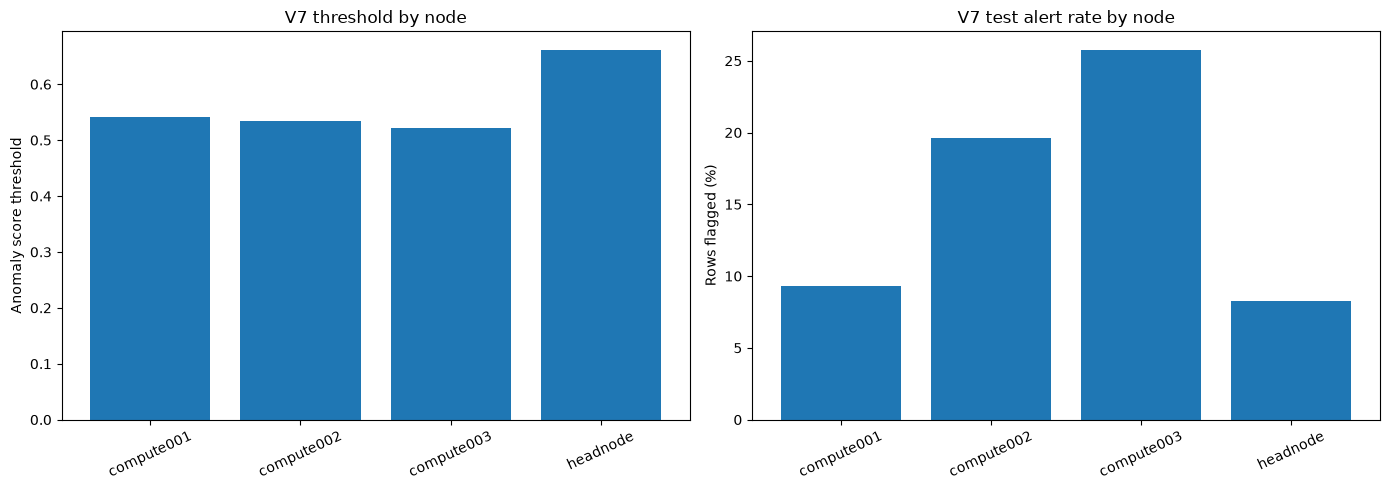

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(threshold_table["node_id"], threshold_table["threshold"])
axes[0].set_title("V7 threshold by node")
axes[0].set_ylabel("Anomaly score threshold")
axes[0].tick_params(axis="x", rotation=25)

flag_rates = (
    test_scored.groupby(NODE_COLUMN)["predicted_anomaly"]
    .mean().reindex(threshold_table["node_id"])
)
axes[1].bar(flag_rates.index, flag_rates.values * 100)
axes[1].set_title("V7 test alert rate by node")
axes[1].set_ylabel("Rows flagged (%)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

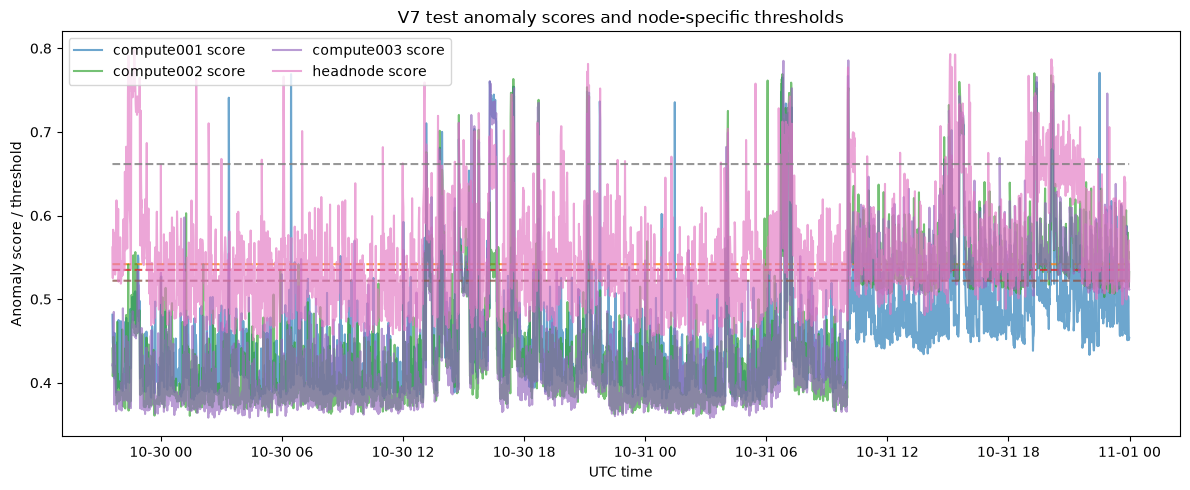

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
for node, group in test_scored.groupby(NODE_COLUMN):
    ax.plot(group[TIME_COLUMN], group["anomaly_score"], label=f"{node} score", alpha=0.65)
    ax.plot(group[TIME_COLUMN], group["threshold"], linestyle="--", alpha=0.8)
ax.set_title("V7 test anomaly scores and node-specific thresholds")
ax.set_xlabel("UTC time")
ax.set_ylabel("Anomaly score / threshold")
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

## 12. Interpret the results before claiming V7 is better

V7 is promising only if it improves the intended detection objective without creating an unacceptable alert burden.

Review:
- Does the headnode alert rate become more reasonable, without hiding genuine headnode anomalies?
- Does recall improve while precision and false alerts per hour remain operationally acceptable?
- Does performance improve for compute001/002/003 individually?
- Does the broad target capture the high-utilisation periods you intend to flag?
- Are validation thresholds based on actual positives, or did they fall back to clean-training quantiles?
- Are there enough labelled incidents per node to make the metrics meaningful?

**Do not declare a win based only on F1.** Also inspect the exported alert-episode counts and operational meaning of labels. Detection delay and event-level matching are not calculated in this notebook and require a separate events.csv correlation step.

## 13. Export the V7 model bundle and report

In [18]:
bundle = {
    "model_version": "v7_global_iforest_per_node_thresholds",
    "model": global_model,
    "feature_columns": feature_columns,
    "imputation_medians": imputation_medians.to_dict(),
    "node_thresholds": {str(k): float(v) for k, v in node_thresholds.items()},
    "global_comparison_threshold": global_threshold,
    "threshold_method": "validation_max_f1_only_with_minimum_positive_rows_and_distinct_events_else_clean_train_quantile",
    "fallback_quantile": FALLBACK_QUANTILE,
    "calibration_target": CALIBRATION_TARGET,
    "score_direction": "higher_is_more_anomalous",
    "node_column": NODE_COLUMN,
    "time_column": TIME_COLUMN,
    "split_metadata": {
        "train_end_time": str(train_end_time),
        "validation_end_time": str(val_end_time),
        "test_start_time": str(test_df[TIME_COLUMN].min()),
        "dataset_rows": int(len(df))
    },
    "minimum_validation_positive_rows": MIN_VALIDATION_POSITIVE_ROWS,
    "minimum_validation_event_ids": MIN_VALIDATION_EVENT_IDS,
    "config": {
        "n_estimators": N_ESTIMATORS,
        "random_state": RANDOM_STATE,
        "train_fraction": TRAIN_FRACTION,
        "validation_fraction": VALIDATION_FRACTION
    }
}

bundle_path = MODEL_DIR / "hpc_isolation_forest_v7_per_node_thresholds.joblib"
joblib.dump(bundle, bundle_path)

test_scored.to_parquet(REPORT_DIR / "v7_test_scored.parquet", index=False)
overall_metrics.to_csv(REPORT_DIR / "v7_overall_test_metrics.csv", index=False)

report = {
    "model_version": bundle["model_version"],
    "rows": int(len(df)),
    "nodes": sorted(df[NODE_COLUMN].dropna().astype(str).unique().tolist()),
    "features": feature_columns,
    "thresholds": bundle["node_thresholds"],
    "global_comparison_threshold": float(global_threshold),
    "global_comparison_threshold_source": global_threshold_source,
    "threshold_table": threshold_rows,
    "overall_test_metrics": overall_rows,
    "fit_seconds": fit_seconds,
    "warning": "Development diagnostic only; prior test period has been inspected during V6 development."
}
with open(REPORT_DIR / "v7_run_summary.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("Saved bundle:", bundle_path)
print("Saved report directory:", REPORT_DIR)

Saved bundle: C:\Users\Admin\Documents\chpc\capstone project\models\hpc_isolation_forest_v7_per_node_thresholds.joblib
Saved report directory: C:\Users\Admin\Documents\chpc\capstone project\data\feature_engineering_duckdb_v6\v7_per_node_threshold_report


## 14. Inference smoke test

This verifies that the saved bundle can be loaded and that node-specific thresholds are applied. It does not prove production readiness.

In [19]:
loaded = joblib.load(bundle_path)
sample = X_test.head(20).copy()
sample_nodes = test_df.loc[sample.index, NODE_COLUMN].astype(str)

sample_scores = -loaded["model"].score_samples(sample)
sample_thresholds = sample_nodes.map(loaded["node_thresholds"]).to_numpy()
sample_predictions = (sample_scores >= sample_thresholds).astype(int)

assert len(sample_predictions) == len(sample)
assert np.isfinite(sample_scores).all()
assert np.isfinite(sample_thresholds).all()
print("V7 reload and node-threshold inference: PASS")
print("Sample predictions:", sample_predictions.tolist())

V7 reload and node-threshold inference: PASS
Sample predictions: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 15. V7 conclusion template

Complete this after running the notebook:

- Global model fit rows:
- Per-node thresholds and their calibration source:
- Operational-event Average Precision (AP) / precision / recall / F1:
- Broad-anomaly AP / precision / recall / F1:
- Benchmark-active AP / precision / recall / F1:
- Node with highest alert rate:
- Headnode behaviour compared with V6:
- False alerts per hour / alert episodes:
- Does V7 justify investigating V8? Why?
- Limitations and label-quality concerns:

**Decision rule:** Proceed to V8 only if node-specific thresholding does not adequately address the node-level score-distribution or detection differences, and the evidence suggests that nodes genuinely require different learned normal-behaviour models.